# Seawater RO design with exact gradients (`difflow_water`)

A seawater reverse-osmosis plant with a pressure exchanger, in `difflow_water`:

- seawater properties from Sharqawy, Lienhard & Zubair (2010);
- a plug-flow RO stage (solution-diffusion, film-theory polarization, feed-channel friction);
- a pressure exchanger and two pumps;
- the levelized cost of water (LCOW) with WaterTAP's default costing.

This notebook covers:

1. Seawater osmotic pressure.
2. One RO stage and its profile along the membrane.
3. The plant: recovery, specific energy, LCOW.
4. Exact gradients of the LCOW.
5. Minimizing the LCOW over RO pressure and membrane area, with limits on brine and permeate salinity.

The same plant agrees with WaterTAP 1.8.0 to within 0.3 % (`benchmarks/watertap/`).
Sources, verification status and what is ILLUSTRATIVE: `docs/unit-operations-water.md`.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

import difflow_water as dw
from difflow_water import seawater as sw

## 1. Seawater osmotic pressure

`osmotic_pressure(T, S) = phi(T, S) m rho_w R T`, with the osmotic coefficient from Sharqawy et al. (2010), Eq. 49 (valid for 10-120 g/kg).

35 g/kg, 25 C: 25.9 bar


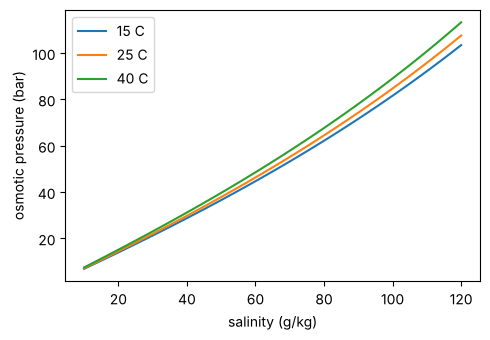

In [2]:
S = jnp.linspace(0.01, 0.12, 50)
fig, ax = plt.subplots(figsize=(5, 3.5))
for T in (288.15, 298.15, 313.15):
    ax.plot(S * 1e3, sw.osmotic_pressure(T, S) / 1e5, label=f"{T - 273.15:.0f} C")
ax.set_xlabel("salinity (g/kg)"); ax.set_ylabel("osmotic pressure (bar)"); ax.legend()
plt.tight_layout()
print(f"35 g/kg, 25 C: {float(sw.osmotic_pressure(298.15, 0.035)) / 1e5:.1f} bar")

## 2. One RO stage

1 L/s of 35 g/kg seawater at 65 bar through 50 m² of membrane. `A_w` and `B` are the water and salt permeability coefficients in WaterTAP's convention (the values WaterTAP's `RO_with_energy_recovery` example uses).

In [3]:
feed_hp = dw.make_seawater_stream(flow_vol=1e-3, salinity=0.035, P=65e5)
ro = dw.ROStage(dw.ROStageParams(A_w=4.2e-12, B=3.5e-8, area=50.0))
conc, perm, info = ro(feed_hp)
for k in ("recovery_mass_water", "salt_rejection", "salinity_permeate", "salinity_concentrate",
          "deltaP", "max_cp_modulus", "min_driving_pressure"):
    print(f"{k:22s} {float(info[k]):.4g}")

recovery_mass_water    0.4238
salt_rejection         0.9931
salinity_permeate      0.0002423
salinity_concentrate   0.05906
deltaP                 -2.127e+05
max_cp_modulus         1.297
min_driving_pressure   1.045e+06


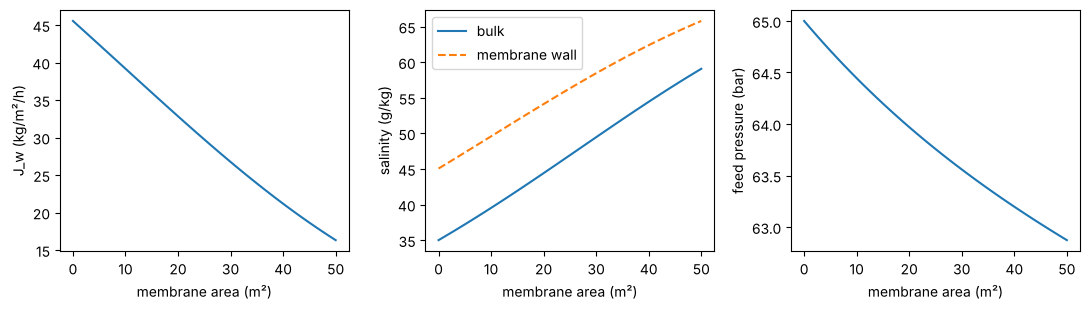

In [4]:
pr = info["profile"]
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2))
axs[0].plot(pr["area"], pr["J_w"] * 3600, label="water flux")
axs[0].set_ylabel("J_w (kg/m²/h)")
axs[1].plot(pr["area"], pr["salinity"] * 1e3, label="bulk")
axs[1].plot(pr["area"], pr["salinity_wall"] * 1e3, "--", label="membrane wall")
axs[1].set_ylabel("salinity (g/kg)"); axs[1].legend()
axs[2].plot(pr["area"], pr["pressure"] / 1e5)
axs[2].set_ylabel("feed pressure (bar)")
for a in axs: a.set_xlabel("membrane area (m²)")
plt.tight_layout()

## 3. The plant

Intake seawater at 1 atm. The pressure exchanger pressurizes as much seawater as there is concentrate; the high-pressure pump takes the rest; a booster tops up the exchanger's outlet.

In [5]:
feed = dw.make_seawater_stream(flow_vol=1e-3, salinity=0.035)
ro_params = dw.ROStageParams(A_w=4.2e-12, B=3.5e-8, area=50.0)
r = dw.swro_performance(feed, ro_params, ro_pressure=65e5)
print(f"recovery          {float(r['recovery']):.3f}")
print(f"permeate salinity {float(r['salinity_permeate']) * 1e6:.0f} mg/kg")
print(f"brine salinity    {float(r['salinity_brine']) * 1e3:.1f} g/kg")
print(f"SEC               {float(r['SEC']):.3f} kWh/m³")
print(f"LCOW              {float(r['LCOW']):.4f} USD/m³")
print(f"HP pump {float(r['work_P1']) / 1e3:.2f} kW, booster {float(r['work_P2']) / 1e3:.2f} kW")

recovery          0.424
permeate salinity 242 mg/kg
brine salinity    59.1 g/kg
SEC               2.470 kWh/m³
LCOW              0.4104 USD/m³
HP pump 3.36 kW, booster 0.38 kW


## 4. Exact gradients

The LCOW as a function of RO pressure (bar), membrane area (m²) and water permeability. `jax.grad` differentiates through the RK4 integration along the membrane and the local flux solves (implicit-function gradients). A central difference is shown alongside as a check.

In [6]:
def lcow(P_bar, area, A_w=4.2e-12):
    p = dw.ROStageParams(A_w=A_w, B=3.5e-8, area=area)
    return dw.swro_performance(feed, p, P_bar * 1e5)["LCOW"]

g = jax.grad(lcow, argnums=(0, 1, 2))(65.0, 50.0, 4.2e-12)
fd_P = (lcow(65.01, 50.0) - lcow(64.99, 50.0)) / 0.02
print(f"dLCOW/dP    = {float(g[0]):+.4e} USD/m³ per bar   (central difference {float(fd_P):+.4e})")
print(f"dLCOW/darea = {float(g[1]):+.4e} USD/m³ per m²")
print(f"dLCOW/dA_w x A_w = {float(g[2]) * 4.2e-12:+.4e} USD/m³ (elasticity-like)")

dLCOW/dP    = +1.5338e-03 USD/m³ per bar   (central difference +1.5338e-03)
dLCOW/darea = -3.5946e-04 USD/m³ per m²
dLCOW/dA_w x A_w = -6.4397e-02 USD/m³ (elasticity-like)


## 5. Minimum LCOW

Minimize the LCOW over RO pressure and area subject to

- brine salinity ≤ 70 g/kg (a stand-in for a scaling/discharge limit; carbonate and sulfate scaling are not modelled yet),
- permeate salinity ≤ 500 mg/kg,
- 40 ≤ P ≤ 82 bar, 20 ≤ area ≤ 150 m².

The objective and constraints are one jitted function; SLSQP gets their exact gradients from `jax.jacobian`.

In [7]:
@jax.jit
def plant(x):
    P_bar, area = x[0], x[1]
    out = dw.swro_performance(feed, dw.ROStageParams(A_w=4.2e-12, B=3.5e-8, area=area), P_bar * 1e5)
    return jnp.stack([out["LCOW"], out["salinity_brine"], out["salinity_permeate"]])

jac = jax.jit(jax.jacobian(plant))
cons = [
    {"type": "ineq", "fun": lambda x: 0.070 - float(plant(x)[1]),
     "jac": lambda x: -np.asarray(jac(x)[1])},
    {"type": "ineq", "fun": lambda x: 5e-4 - float(plant(x)[2]),
     "jac": lambda x: -np.asarray(jac(x)[2])},
]
x0 = np.array([65.0, 50.0])
res = minimize(lambda x: float(plant(x)[0]), x0, jac=lambda x: np.asarray(jac(x)[0]),
               bounds=[(40.0, 82.0), (20.0, 150.0)], constraints=cons, method="SLSQP")
print(res.message)
P_opt, A_opt = res.x
best = dw.swro_performance(feed, dw.ROStageParams(A_w=4.2e-12, B=3.5e-8, area=A_opt), P_opt * 1e5)
print(f"P = {P_opt:.1f} bar, area = {A_opt:.1f} m²")
print(f"LCOW {float(best['LCOW']):.4f} USD/m³ (start {float(plant(x0)[0]):.4f}), "
      f"SEC {float(best['SEC']):.3f} kWh/m³, recovery {float(best['recovery']):.3f}, "
      f"brine {float(best['salinity_brine']) * 1e3:.1f} g/kg")

Optimization terminated successfully


P = 58.2 bar, area = 51.6 m²
LCOW 0.4043 USD/m³ (start 0.4104), SEC 2.291 kWh/m³, recovery 0.367, brine 54.0 g/kg


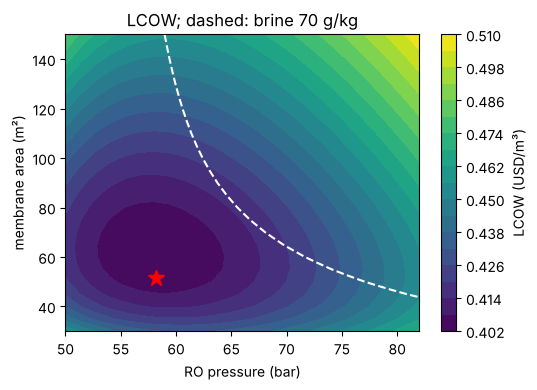

In [8]:
Ps = np.linspace(50, 82, 25); As = np.linspace(30, 150, 25)
Z = np.array([[float(plant(jnp.array([p, a]))[0]) for p in Ps] for a in As])
Sb = np.array([[float(plant(jnp.array([p, a]))[1]) for p in Ps] for a in As])
fig, ax = plt.subplots(figsize=(5.5, 4))
cs = ax.contourf(Ps, As, Z, levels=20, cmap="viridis"); fig.colorbar(cs, label="LCOW (USD/m³)")
ax.contour(Ps, As, Sb, levels=[0.070], colors="w", linestyles="--")
ax.plot(P_opt, A_opt, "r*", ms=12)
ax.set_xlabel("RO pressure (bar)"); ax.set_ylabel("membrane area (m²)")
ax.set_title("LCOW; dashed: brine 70 g/kg")
plt.tight_layout()

## Notes

- At these costs the optimum is interior: neither salinity limit is active there. Cheaper membrane or dearer electricity moves it toward higher recovery and the brine limit.
- The costs are WaterTAP's default parameters (USD 2018): a benchmark convention for comparing with WaterTAP, not a cost estimate for a real plant.
- The feed-channel correlations (mass-transfer coefficient, friction factor) are WaterTAP's and are unverified against their papers; see the references table in `docs/unit-operations-water.md`.
- Recovery here is limited by a brine salinity bound. Scaling (calcite, gypsum) limits need the carbonate chemistry planned for a later phase.